# Détection d'anomalies routières : exploration du dataset RoadAnomaly

---
## 0. Préparation de l'environnement
Objectif : importer les bibliothèques, fixer la graine aléatoire et vérifier que le notebook trouve bien le dataset.

In [2]:
import os, json
import numpy as np
import pandas as pd
from PIL import Image
import random
import matplotlib.pyplot as plt

Le découpage train/val/test, les augmentations et l'initialisation du réseau utilisent le hasard. Fixer la graine (`SEED = 42`) garantit que **les mêmes résultats seront obtenus à chaque exécution**

In [3]:
# Reproductibilité : on fixe la graine une fois pour toutes
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [5]:
# Chemins du dataset
ROOT = "."
FRAMES = os.path.join(ROOT, "frames")

print("Dossier de travail :", os.getcwd())
print("ROOT existe        :", os.path.exists(ROOT))
print("frames existe      :", os.path.exists(FRAMES))
print("frame_list.json    :", os.path.exists(os.path.join(ROOT, "frame_list.json")))

Dossier de travail : c:\Users\arije\Downloads\RoadAnomaly-main\RoadAnomaly-main\RoadAnomaly
ROOT existe        : True
frames existe      : True
frame_list.json    : True


#### Interprétation
Le dataset est accessible

## 1. Chargement et intégrité des données
Objectif : s'assurer que **chaque image possède bien son masque**, que leurs dimensions correspondent et que les formats sont ceux attendus.

In [6]:
# Lecture de la liste des images du dataset
with open(os.path.join(ROOT, "frame_list.json")) as f:
    frame_list = json.load(f)

print("Type             :", type(frame_list))
print("Nombre d'entrées :", len(frame_list))
print("3 premiers       :", frame_list[:3])

Type             : <class 'list'>
Nombre d'entrées : 60
3 premiers       : ['animals01_Guiguinto_railway_station_Calves.webp', 'animals02_Zagori_On_the_road_to_Papigko.webp', 'animals03_Zebras_in_the_road.webp']


#### Interprétation
Le dataset contient **60 images**. Les noms sont donnés **avec l'extension `.webp`** et leur préfixe indique la catégorie de l'anomalie (`animals`, ...), information qui sera exploitée en section 5.

Fonction `get_paths` : retrouver l'image et le masque à partir d'un nom


In [8]:
#construire les chemins image et masque
def get_paths(name):
    """Renvoie (nom sans extension, chemin de l'image, chemin du masque)."""

    # On enlève l'extension (.webp) si elle est déjà dans le nom,
    # pour éviter d'obtenir "nom.webp.webp" plus bas
    base = os.path.splitext(name)[0]

    # Chemin de l'image : frames/<nom>.webp
    img_path = os.path.join(FRAMES, base + ".webp")

    # Chemin du masque : frames/<nom>.labels/labels_semantic.png
    # (structure décrite dans le README du dataset)
    mask_path = os.path.join(FRAMES, base + ".labels", "labels_semantic.png")

    # On renvoie les trois valeurs pour pouvoir les utiliser ensuite
    return base, img_path, mask_path

Test de `get_paths` sur la première image

In [9]:
# --- Test sur la première image de la liste ---

# On appelle la fonction avec le premier nom de frame_list
base, img_p, mask_p = get_paths(frame_list[0])

# On affiche le nom trouvé
print("Nom         :", base)

# On affiche le chemin de l'image et si le fichier existe réellement (True/False)
print("Image       :", img_p, "->", os.path.exists(img_p))

# On affiche le chemin du masque et si le fichier existe réellement (True/False)
print("Masque      :", mask_p, "->", os.path.exists(mask_p))

Nom         : animals01_Guiguinto_railway_station_Calves
Image       : .\frames\animals01_Guiguinto_railway_station_Calves.webp -> True
Masque      : .\frames\animals01_Guiguinto_railway_station_Calves.labels\labels_semantic.png -> True


#### Interprétation
Les chemins de l'image et du masque existent tous les deux : la structure décrite dans le README est confirmée et `get_paths` est correcte.

Pour chaque image, on vérifie l'existence des deux fichiers, leurs dimensions et leur mode de couleur. Les résultats sont rangés dans le tableau `df`, qui servira de base au reste de l'étude.

In [12]:
#vérifier TOUTES les images et leurs masques


# Liste vide qui va contenir une "ligne" de résultats par image
rows = []

# On boucle sur chaque nom présent dans frame_list.json
for name in frame_list:

    # On retrouve le nom propre et les deux chemins grâce à la fonction de la cellule 4
    base, img_p, mask_p = get_paths(name)

    # On vérifie si les deux fichiers existent sur le disque (True/False)
    img_ok = os.path.exists(img_p)
    mask_ok = os.path.exists(mask_p)

    # On prépare la ligne de résultats pour cette image
    row = {"name": base, "img_exists": img_ok, "mask_exists": mask_ok}

    # On n'ouvre les fichiers que si les deux existent (sinon ça planterait)
    if img_ok and mask_ok:

        # Image.open ne charge pas toute l'image : il lit seulement l'en-tête, c'est rapide
        img = Image.open(img_p)
        mask = Image.open(mask_p)

        # Largeur et hauteur en pixels (format PIL : (largeur, hauteur))
        row["img_w"], row["img_h"] = img.size
        row["mask_w"], row["mask_h"] = mask.size

        # Mode de couleur : RGB pour l'image, on s'attend à "L" ou "P" pour le masque
        row["img_mode"] = img.mode
        row["mask_mode"] = mask.mode

        # True si l'image et le masque ont exactement la même taille
        row["same_size"] = (img.size == mask.size)

    # On ajoute cette ligne à la liste
    rows.append(row)

# On transforme la liste de lignes en tableau pandas
df = pd.DataFrame(rows)

# --- Résumé des vérifications ---

# Nombre total d'images analysées
print("Nombre d'images          :", len(df))

# Combien d'images ont leur fichier image / leur masque
print("Images trouvées          :", df["img_exists"].sum())
print("Masques trouvés          :", df["mask_exists"].sum())

# Combien de paires ont la même taille (doit être égal au nombre d'images)
print("Paires de même taille    :", df["same_size"].sum())

# Les modes de couleur rencontrés (pour savoir comment lire les fichiers)
print("Modes image              :", df["img_mode"].unique())
print("Modes masque             :", df["mask_mode"].unique())

# On affiche les 5 premières lignes du tableau pour voir à quoi il ressemble
df.head()

Nombre d'images          : 60
Images trouvées          : 60
Masques trouvés          : 60
Paires de même taille    : 60
Modes image              : ['RGB']
Modes masque             : ['L']


,name,img_exists,mask_exists,img_w,img_h,mask_w,mask_h,img_mode,mask_mode,same_size
0,animals01_Guiguinto_railway_station_Calves,True,True,1280,720,1280,720,RGB,L,True
1,animals02_Zagori_On_the_road_to_Papigko,True,True,1280,720,1280,720,RGB,L,True
2,animals03_Zebras_in_the_road,True,True,1280,720,1280,720,RGB,L,True
3,animals04_17_animal_casualties_so_far_in_2006,True,True,1280,720,1280,720,RGB,L,True
4,animals05_cows_near_Phonsavan_Laos,True,True,1280,720,1280,720,RGB,L,True


#### Interprétation
| Vérification | Résultat |
|---|---|
| Images trouvées | 60 / 60 |
| Masques trouvés | 60 / 60 |
| Paires de même taille | 60 / 60 |
| Mode des images | RGB (3 canaux) |
| Mode des masques | L (niveaux de gris : un entier par pixel) |

**Aucune paire manquante ni désalignée.** Le mode `L` confirme que les masques contiennent des entiers (et non des couleurs) : on peut donc les lire directement avec `numpy`.

### 1.5 Résolutions, ratios d'aspect et formats
Objectif : savoir si les images ont des tailles différentes, ce qui déterminerait la façon de les redimensionner avant l'entraînement.

In [13]:
# ============================================================
# BUT DE LA CELLULE :
# Résumer les tailles des images (min, max, médiane), compter les
# résolutions différentes et calculer les ratios d'aspect.
# Ces chiffres serviront à choisir la taille de redimensionnement
# pour l'entraînement, et seront cités dans le rapport.
# ============================================================

# Ratio d'aspect = largeur / hauteur (1.0 = carré, 1.78 = format 16:9)
df["aspect"] = df["img_w"] / df["img_h"]

# Nombre de pixels par image (largeur x hauteur)
df["n_pixels"] = df["img_w"] * df["img_h"]

# --- Résumé statistique : min, max, médiane, moyenne ---

# On sélectionne les colonnes qui nous intéressent
cols = ["img_w", "img_h", "aspect", "n_pixels"]

# describe() calcule count, mean, std, min, 25%, 50% (médiane), 75%, max
print(df[cols].describe().round(2))

# --- Résolutions distinctes ---

# On crée une colonne texte "largeurxhauteur", par exemple "1280x720"
df["resolution"] = df["img_w"].astype(str) + "x" + df["img_h"].astype(str)

# Nombre de résolutions différentes dans le dataset
print("\nNombre de résolutions différentes :", df["resolution"].nunique())

# Les 10 résolutions les plus fréquentes, avec leur nombre d'images
print(df["resolution"].value_counts().head(10))

# --- Formats de fichiers ---

# Extension réelle des images (doit être .webp d'après le README)
print("\nFormat des images :", [".webp"], "| Format des masques :", [".png"])

        img_w  img_h  aspect  n_pixels
count    60.0   60.0   60.00      60.0
mean   1280.0  720.0    1.78  921600.0
std       0.0    0.0    0.00       0.0
min    1280.0  720.0    1.78  921600.0
25%    1280.0  720.0    1.78  921600.0
50%    1280.0  720.0    1.78  921600.0
75%    1280.0  720.0    1.78  921600.0
max    1280.0  720.0    1.78  921600.0

Nombre de résolutions différentes : 1
resolution
1280x720    60
Name: count, dtype: int64

Format des images : ['.webp'] | Format des masques : ['.png']


#### Interprétation
Les 60 images ont **exactement la même résolution : 1280 × 720** (écart-type nul), soit un ratio 16:9 (1,78). Les images sont en `.webp` et les masques en `.png`.

**Décision :** pas de déformation à craindre. On redimensionnera en **conservant le ratio 16:9**, avec des dimensions multiples de 32 (exigence des architectures U-Net/DeepLab), par exemple 512 × 288 ou 640 × 352. Le choix final tiendra compte des petites anomalies (voir section 4.2).

## 2. Analyse des masques de segmentation
Objectif : comprendre les **valeurs réelles** contenues dans les masques `labels_semantic.png` (le README annonce 0 = fond et 2 = anomalie), mesurer le déséquilibre de classes et définir la conversion en masque binaire.

Les masques vus sous forme orange/noir sont colorisés pour l'affichage : le fichier réel contient des entiers. On le vérifie sur la première image.

In [ ]:

# On prend la première image de la liste
base, img_p, mask_p = get_paths(frame_list[0])

# On ouvre le masque et on le convertit en tableau numpy (matrice de nombres)
mask = np.array(Image.open(mask_p))

# Nom de l'image analysée
print("Image       :", base)

# Forme du tableau : (hauteur, largeur) car le masque est en niveaux de gris (mode L)
print("Forme       :", mask.shape)

# Type des pixels (uint8 = entiers de 0 à 255)
print("Type        :", mask.dtype)

# Valeurs distinctes présentes dans le masque, avec le nombre de pixels de chacune
valeurs, comptes = np.unique(mask, return_counts=True)

# On parcourt chaque valeur trouvée avec son nombre de pixels
for v, c in zip(valeurs, comptes):
    # On affiche la valeur, le nombre de pixels et le pourcentage de l'image
    print(f"Valeur {v:3d} : {c:8d} pixels ({100 * c / mask.size:.2f} %)")

Image       : animals01_Guiguinto_railway_station_Calves
Forme       : (720, 1280)
Type        : uint8
Valeur   0 :   859783 pixels (93.29 %)
Valeur   2 :    61817 pixels (6.71 %)


#### Interprétation
Le masque a la forme `(720, 1280)` en `uint8` et ne contient que les valeurs **0 (fond, 93,29 %)** et **2 (anomalie, 6,71 %)**, ce qui est conforme au README. Ce n'est qu'**une image sur 60** : il faut vérifier toutes les autres avant de conclure.

 vérifier qu'aucune autre valeur (par exemple 255 = « void ») n'existe, qu'aucun masque n'est vide, et mesurer le **déséquilibre de classes**.

In [ ]:

# Compteur global : {valeur du pixel: nombre total de pixels dans tout le dataset}
compte_global = {}

# Liste qui contiendra, pour chaque image, la proportion de pixels d'anomalie (valeur 2)
prop_anomalie = []

# Liste qui contiendra, pour chaque image, l'ensemble des valeurs présentes dans son masque
valeurs_par_image = []

# On parcourt toutes les images du dataset
for name in frame_list:

    # On récupère le chemin du masque grâce à notre fonction
    base, img_p, mask_p = get_paths(name)

    # On charge le masque en tableau numpy
    mask = np.array(Image.open(mask_p))

    # On liste les valeurs distinctes et leur nombre de pixels
    valeurs, comptes = np.unique(mask, return_counts=True)

    # On ajoute ces comptes au compteur global
    for v, c in zip(valeurs, comptes):
        compte_global[int(v)] = compte_global.get(int(v), 0) + int(c)

    # On mémorise les valeurs présentes dans ce masque (ex: [0, 2])
    valeurs_par_image.append([int(v) for v in valeurs])

    # Proportion de pixels d'anomalie (valeur 2) dans cette image
    prop_anomalie.append(float((mask == 2).sum()) / mask.size)

# On ajoute ces informations au tableau df
df["valeurs"] = valeurs_par_image
df["prop_anomalie"] = prop_anomalie

# --- Résumé global ---

# Nombre total de pixels du dataset (60 x 921 600)
total = sum(compte_global.values())

print("Valeurs présentes dans le dataset :", sorted(compte_global.keys()))
for v in sorted(compte_global):
    print(f"Valeur {v:3d} : {compte_global[v]:11d} pixels ({100 * compte_global[v] / total:.2f} %)")

# Les différentes combinaisons de valeurs rencontrées dans les masques
print("\nCombinaisons de valeurs par image :")
print(df["valeurs"].astype(str).value_counts())

# Nombre de masques sans aucun pixel d'anomalie
print("\nMasques sans anomalie :", int((df["prop_anomalie"] == 0).sum()))

# Statistiques de la proportion d'anomalie par image (en %)
print("\nProportion d'anomalie par image (%) :")
print((df["prop_anomalie"] * 100).describe().round(2))

Valeurs présentes dans le dataset : [0, 2]
Valeur   0 :    49849587 pixels (90.15 %)
Valeur   2 :     5446413 pixels (9.85 %)

Combinaisons de valeurs par image :
valeurs
[0, 2]    60
Name: count, dtype: int64

Masques sans anomalie : 0

Proportion d'anomalie par image (%) :
count    60.00
mean      9.85
std      10.06
min       0.37
25%       1.80
50%       6.62
75%      13.80
max      42.33
Name: prop_anomalie, dtype: float64


#### Interprétation
- **Valeurs présentes : uniquement 0 et 2** sur les 60 masques. Il n'y a pas de valeur « void » à ignorer.
- **Fond : 90,15 % des pixels, anomalie : 9,85 %**, soit un rapport d'environ 9 pour 1.
- **Aucun masque vide** : chaque image contient au moins une anomalie.
- **Taille très variable d'une image à l'autre** : de 0,37 % à 42,33 % (médiane 6,62 %, moyenne 9,85 %, écart-type 10,06 %). La moyenne dépasse la médiane : beaucoup de petites anomalies et quelques très grandes.


 Fonction `load_pair` : charger une paire et convertir le masque en binaire
Définition de la conversion utilisée dans tout le projet : **2 (anomalie) → 1** et **0 (fond) → 0**. Cette fonction sera réutilisée telle quelle pour l'entraînement.

In [ ]:


def load_pair(name):
    """Renvoie (image RGB en numpy, masque binaire en numpy) pour un nom de frame."""

    # On récupère les chemins de l'image et du masque
    base, img_p, mask_p = get_paths(name)

    # On charge l'image et on force le mode RGB (3 canaux), puis on convertit en numpy
    img = np.array(Image.open(img_p).convert("RGB"))

    # On charge le masque brut (valeurs 0 et 2)
    mask_raw = np.array(Image.open(mask_p))

    # Conversion binaire : True là où la valeur vaut 2 (anomalie), puis en entiers 0/1
    mask_bin = (mask_raw == 2).astype(np.uint8)

    # On renvoie l'image et le masque binaire
    return img, mask_bin


# --- Test sur la première image ---

# On charge la première paire
img, mask_bin = load_pair(frame_list[0])

# Forme et type de l'image (attendu : (720, 1280, 3), uint8)
print("Image  :", img.shape, img.dtype)

# Forme et type du masque binaire (attendu : (720, 1280), uint8)
print("Masque :", mask_bin.shape, mask_bin.dtype)

# Valeurs du masque binaire (attendu : [0 1])
print("Valeurs du masque binaire :", np.unique(mask_bin))

# Proportion d'anomalie (doit retrouver 6,71 % pour cette image)
print(f"Anomalie : {100 * mask_bin.mean():.2f} %")

Image  : (720, 1280, 3) uint8
Masque : (720, 1280) uint8
Valeurs du masque binaire : [0 1]
Anomalie : 6.71 %


#### Interprétation
L'image est `(720, 1280, 3)` et le masque binaire `(720, 1280)` avec les valeurs `[0 1]`. La proportion d'anomalie retrouvée (**6,71 %**) est identique à celle de la section 2.1 : la conversion est correcte.

---
## 3. Visualisations qualitatives
Objectif : voir les images, leurs masques et leur superposition (overlay) pour comprendre la **diversité des anomalies** et vérifier visuellement la **qualité des annotations**.


`make_overlay` colore en orange les pixels d'anomalie sur l'image ; `show_triplet` affiche côte à côte l'image, le masque et l'overlay.

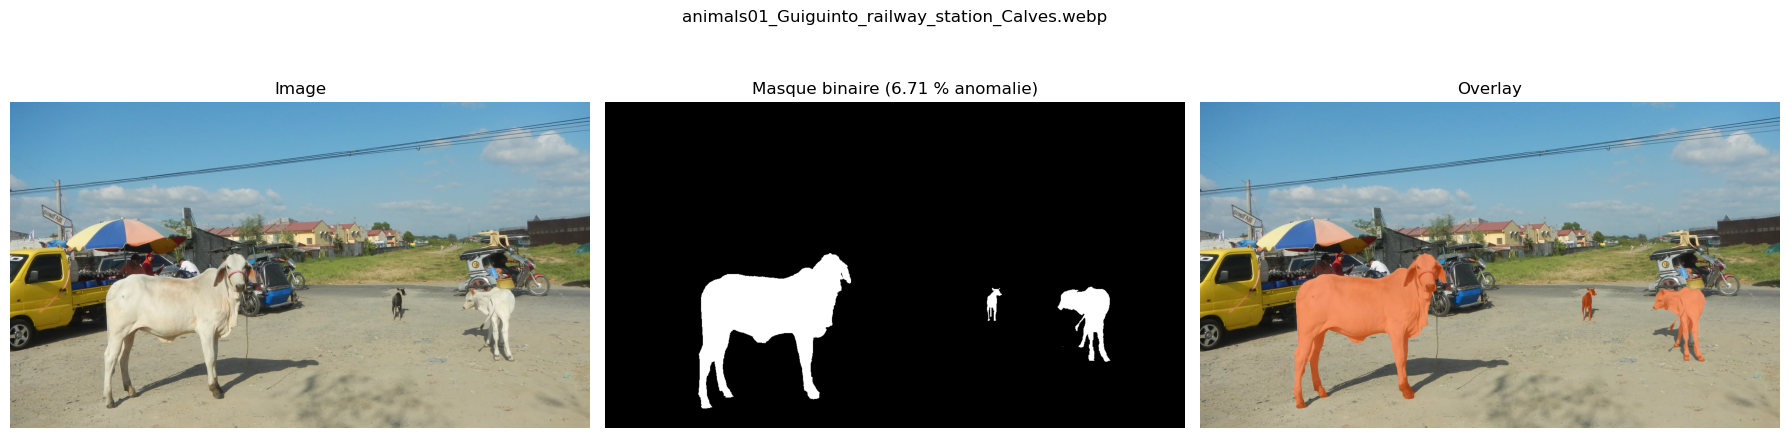

In [ ]:


def make_overlay(img, mask_bin, color=(255, 69, 0), alpha=0.5):
    """Superpose le masque (en couleur) sur l'image avec une transparence alpha."""

    # On copie l'image en float pour pouvoir mélanger les couleurs sans erreur
    out = img.astype(np.float32).copy()

    # On transforme la couleur en tableau numpy (R, G, B)
    color = np.array(color, dtype=np.float32)

    # Sur les pixels d'anomalie uniquement : mélange image (1-alpha) + couleur (alpha)
    out[mask_bin == 1] = (1 - alpha) * out[mask_bin == 1] + alpha * color

    # On revient en entiers 0-255 pour l'affichage
    return out.astype(np.uint8)


def show_triplet(name):
    """Affiche image | masque | overlay pour un nom de frame."""

    # On charge la paire (image, masque binaire)
    img, mask_bin = load_pair(name)

    # On crée une figure avec 3 cases côte à côte
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Case 1 : image originale
    axes[0].imshow(img)
    axes[0].set_title("Image")

    # Case 2 : masque binaire (noir = normal, blanc = anomalie)
    axes[1].imshow(mask_bin, cmap="gray")
    axes[1].set_title(f"Masque binaire ({100 * mask_bin.mean():.2f} % anomalie)")

    # Case 3 : overlay
    axes[2].imshow(make_overlay(img, mask_bin))
    axes[2].set_title("Overlay")

    # On enlève les graduations des axes pour plus de lisibilité
    for ax in axes:
        ax.axis("off")

    # Titre général avec le nom de l'image
    fig.suptitle(name, fontsize=12)
    plt.tight_layout()
    plt.show()


# --- Test sur la première image ---
show_triplet(frame_list[0])

#### Interprétation
Le masque binaire épouse bien les animaux et l'overlay orange recouvre exactement leur silhouette, **sans décalage** : c'est la preuve visuelle de la correspondance image ↔ masque demandée par le sujet. Cette scène contient **plusieurs régions anormales** de tailles très différentes (un grand veau au premier plan et de petits animaux au loin), et les contours sont nets.

 Grille de 12 exemples, triés par taille d'anomalie croissante
Les 12 images sont choisies à intervalles réguliers dans le classement par proportion d'anomalie, pour montrer des cas **très petits, moyens et très grands** (de 0,37 % à 42,33 %).

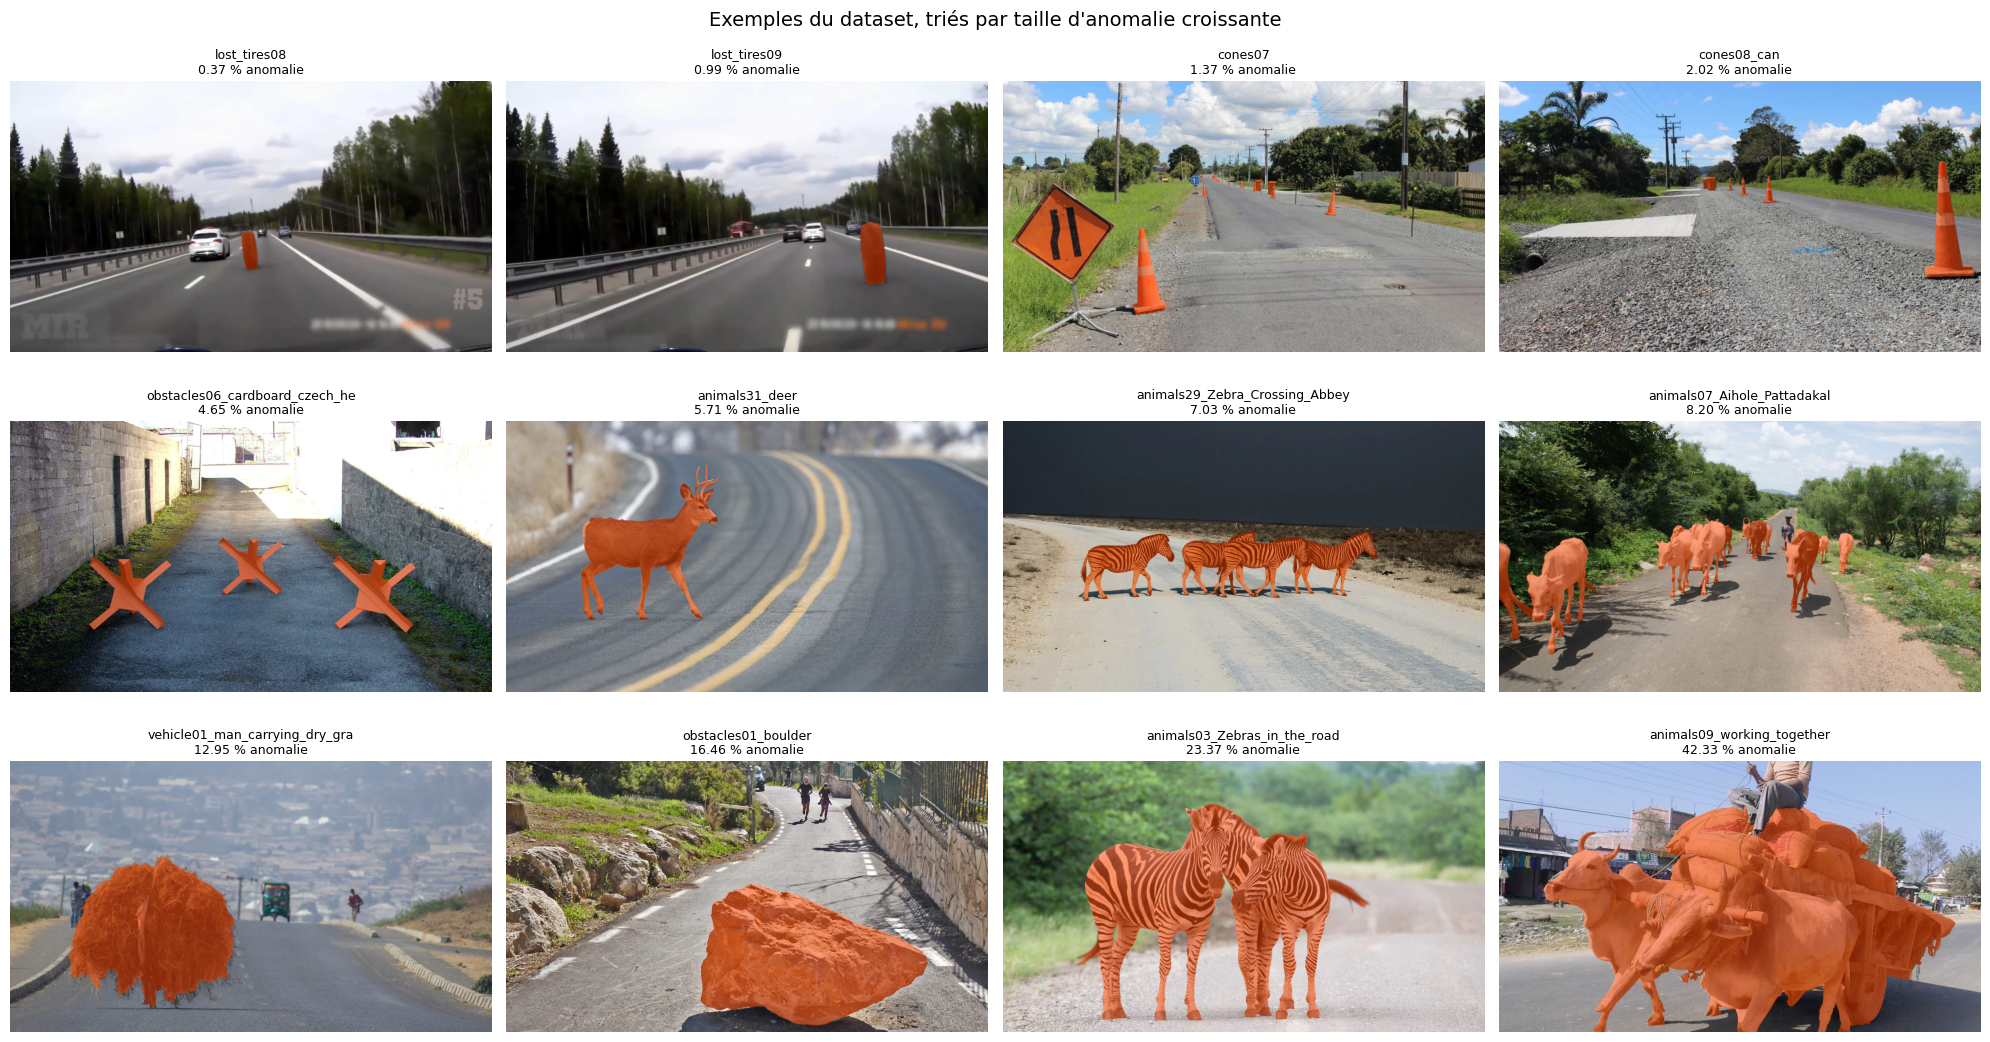

In [ ]:


# On trie les images par proportion d'anomalie croissante
# (df["prop_anomalie"] a été calculé à la cellule 9)
ordre = df.sort_values("prop_anomalie").index.tolist()

# On prend 12 positions régulièrement espacées dans ce classement :
# on obtient ainsi des anomalies très petites, moyennes et très grandes
positions = np.linspace(0, len(ordre) - 1, 12).astype(int)
indices = [ordre[p] for p in positions]

# Grille de 3 lignes x 4 colonnes
fig, axes = plt.subplots(3, 4, figsize=(20, 11))

# axes.ravel() aplatit la grille en une liste de 12 cases
for ax, i in zip(axes.ravel(), indices):

    # On récupère le nom de l'image et on charge sa paire
    name = df.loc[i, "name"]
    img, mask_bin = load_pair(name)

    # On affiche l'overlay (image + anomalie en orange)
    ax.imshow(make_overlay(img, mask_bin))

    # Titre : nom raccourci (30 caractères) + proportion d'anomalie
    ax.set_title(f"{name[:30]}\n{100 * mask_bin.mean():.2f} % anomalie", fontsize=9)

    # On enlève les axes pour plus de lisibilité
    ax.axis("off")

# Titre général de la figure
fig.suptitle("Exemples du dataset, triés par taille d'anomalie croissante", fontsize=14)
plt.tight_layout()
plt.show()

#### Interprétation
- **Cinq familles d'anomalies** apparaissent dans les noms : `animals` (cerf, zèbres, vaches), `cones` (cônes de chantier), `lost_tires` (pneus perdus), `obstacles` (rocher, carton, obstacles répétés) et `vehicle` (véhicule chargé de foin).
- **Très petites anomalies** (`lost_tires`, `cones` : moins de 2 %) : objets minuscules sur une route lointaine, donc les plus difficiles à détecter.
- **Très grandes anomalies** (`animals09_working_together`, 42 %) : animaux superposés dont le masque fusionne plusieurs objets en un seul bloc.
- **Contexte très varié** : autoroute, route de campagne, chemin de terre, rue en ville, avec des éclairages et des caméras différents.
- **Annotations globalement nettes**, mais approximatives sur les formes complexes (pattes des zèbres, foin).

---
## 4. Statistiques quantitatives
Objectif : quantifier le **déséquilibre de classes**, la **taille et le nombre des anomalies**, leur **position dans l'image** et les **statistiques de couleur**. Chaque résultat justifie un choix pour l'entraînement.

Distribution de la proportion d'anomalie et déséquilibre global
À gauche : combien d'images ont une petite ou une grande anomalie. À droite : répartition globale des pixels fond / anomalie.

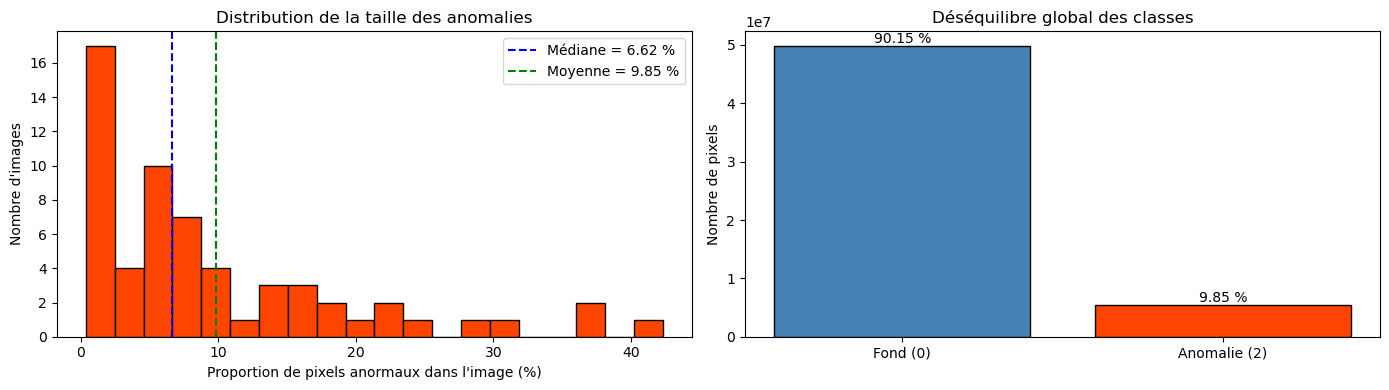

In [ ]:

# On convertit la proportion (0 à 1) en pourcentage (0 à 100)
pct = df["prop_anomalie"] * 100

# Figure avec 2 graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# --- Graphique 1 : histogramme de la proportion d'anomalie par image ---
axes[0].hist(pct, bins=20, color="orangered", edgecolor="black")

# Ligne verticale pour la médiane (valeur du milieu)
axes[0].axvline(pct.median(), color="blue", linestyle="--", label=f"Médiane = {pct.median():.2f} %")

# Ligne verticale pour la moyenne
axes[0].axvline(pct.mean(), color="green", linestyle="--", label=f"Moyenne = {pct.mean():.2f} %")

axes[0].set_xlabel("Proportion de pixels anormaux dans l'image (%)")
axes[0].set_ylabel("Nombre d'images")
axes[0].set_title("Distribution de la taille des anomalies")
axes[0].legend()

# --- Graphique 2 : répartition globale des pixels fond / anomalie ---
# compte_global a été calculé à la cellule 9 : {0: nb pixels fond, 2: nb pixels anomalie}
axes[1].bar(["Fond (0)", "Anomalie (2)"],
            [compte_global[0], compte_global[2]],
            color=["steelblue", "orangered"], edgecolor="black")

axes[1].set_ylabel("Nombre de pixels")
axes[1].set_title("Déséquilibre global des classes")

# On écrit le pourcentage au-dessus de chaque barre
total = compte_global[0] + compte_global[2]
for x, v in zip([0, 1], [compte_global[0], compte_global[2]]):
    axes[1].text(x, v, f"{100 * v / total:.2f} %", ha="center", va="bottom")

plt.tight_layout()
plt.show()

#### Interprétation
- **Histogramme asymétrique** : le pic est à gauche (17 images sur 60 ont moins de 2 % d'anomalie) et la queue s'étend jusqu'à 42 %. La moyenne (9,85 %) est supérieure à la médiane (6,62 %).
- **Déséquilibre global** : 90,15 % de fond contre 9,85 % d'anomalie.


 Nombre et taille des régions anormales (composantes connexes)
Une « région » est un groupe de pixels anormaux qui se touchent (`scipy.ndimage.label`). On compte les régions par image et on mesure la taille de chacune 

Régions par image :
count    60.00
mean      6.45
std       9.33
min       1.00
25%       1.00
50%       3.00
75%       8.00
max      58.00
Name: n_regions, dtype: float64

Images avec 1 seule région   : 17
Images avec 2 régions ou plus : 43

Nombre total de régions : 387
Plus petite région (px) : 1
Médiane des régions (px): 98
Plus grande région (px) : 390055
Régions < 500 px        : 244


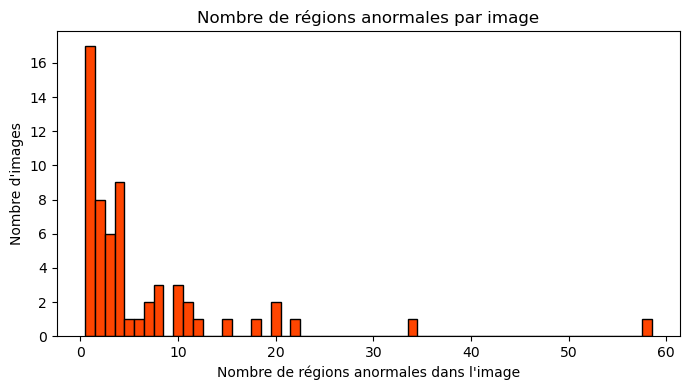

In [ ]:

from scipy import ndimage

# Listes qui vont contenir les résultats
n_regions = []        # nombre de régions par image
tailles_regions = []  # taille (en pixels) de CHAQUE région, toutes images confondues

# On parcourt toutes les images
for name in frame_list:

    # On charge uniquement le masque binaire
    _, mask_bin = load_pair(name)

    # label() repère les groupes de pixels anormaux qui se touchent
    # lab = tableau où chaque région a un numéro (1, 2, 3...), n = nombre de régions
    lab, n = ndimage.label(mask_bin)

    # On mémorise le nombre de régions de cette image
    n_regions.append(n)

    # Taille de chaque région (le [1:] ignore le fond, numéro 0)
    tailles = np.bincount(lab.ravel())[1:]
    tailles_regions.extend(tailles.tolist())

# On ajoute le nombre de régions au tableau df
df["n_regions"] = n_regions

# Conversion en tableau numpy pour faciliter les calculs
tailles_regions = np.array(tailles_regions)

# --- Résumé ---
print("Régions par image :")
print(df["n_regions"].describe().round(2))

# Images avec une seule région, et avec plusieurs
print("\nImages avec 1 seule région   :", int((df["n_regions"] == 1).sum()))
print("Images avec 2 régions ou plus :", int((df["n_regions"] >= 2).sum()))

# Statistiques sur la taille des régions (tous objets confondus)
print("\nNombre total de régions :", len(tailles_regions))
print("Plus petite région (px) :", tailles_regions.min())
print("Médiane des régions (px):", int(np.median(tailles_regions)))
print("Plus grande région (px) :", tailles_regions.max())

# Régions de moins de 500 pixels (quasi invisibles)
print("Régions < 500 px        :", int((tailles_regions < 500).sum()))

# --- Histogramme du nombre de régions par image ---
plt.figure(figsize=(7, 4))
plt.hist(df["n_regions"], bins=range(1, df["n_regions"].max() + 2),
         color="orangered", edgecolor="black", align="left")
plt.xlabel("Nombre de régions anormales dans l'image")
plt.ylabel("Nombre d'images")
plt.title("Nombre de régions anormales par image")
plt.tight_layout()
plt.show()

#### Interprétation
| Mesure | Valeur |
|---|---|
| Images avec 1 seule région | 17 (28 %) |
| Images avec 2 régions ou plus | **43 (72 %)** |
| Régions par image (moyenne / médiane / max) | 6,45 / 3 / 58 |
| Nombre total de régions | 387 |
| Plus petite région | **1 pixel** |
| Région médiane | **98 pixels** |
| Plus grande région | 390 055 pixels (≈ 42 % de l'image) |
| Régions de moins de 500 pixels | **244 sur 387 (63 %)** |

- **La majorité des scènes sont multi-objets** : la tâche est bien de la segmentation sémantique et non la détection d'un seul objet.
- **Beaucoup de régions minuscules** : près de deux tiers font moins de 500 pixels. Après réduction à 512 × 288 (surface divisée par 6,25), une région médiane de 98 pixels n'en ferait plus qu'environ 16. Ce sont soit de vrais objets lointains (cônes, pneus), soit du **bruit d'annotation** (une région d'un seul pixel n'est pas un objet).


Carte de chaleur : où se trouvent les anomalies dans l'image ?
Pour chaque pixel, on calcule la fréquence à laquelle il est anormal sur les 60 images, puis les profils moyens vertical et horizontal. Cela indique s'il existe un **biais de position** et quelles augmentations sont valides.

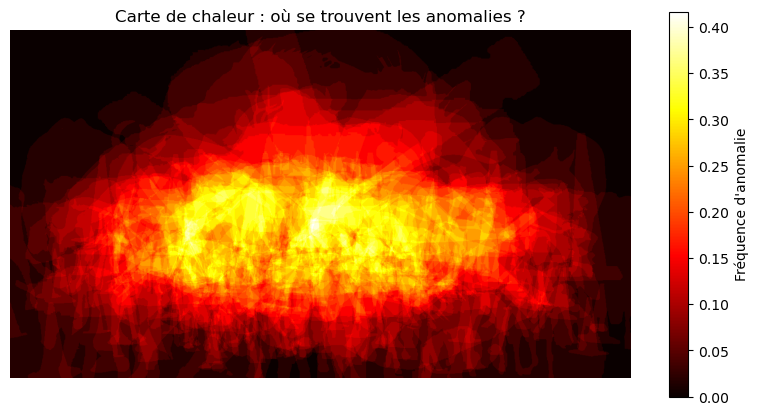

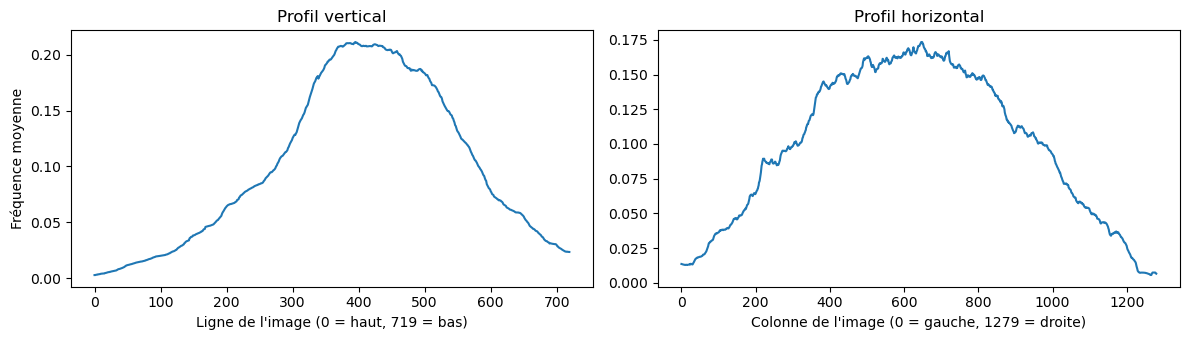

Fréquence maximale : 41.7 %


In [ ]:

# Tableau de zéros de la taille d'un masque (720 x 1280), en float pour additionner
heat = np.zeros((720, 1280), dtype=np.float64)

# On parcourt tous les masques et on les additionne
for name in frame_list:

    # On charge le masque binaire (0 ou 1)
    _, mask_bin = load_pair(name)

    # On ajoute ce masque à la carte : un pixel anormal ajoute 1
    heat += mask_bin

# On divise par le nombre d'images : chaque pixel vaut maintenant
# la probabilité (0 à 1) d'être anormal
heat /= len(frame_list)

# --- Affichage ---
plt.figure(figsize=(10, 5))
plt.imshow(heat, cmap="hot")
plt.colorbar(label="Fréquence d'anomalie")
plt.title("Carte de chaleur : où se trouvent les anomalies ?")
plt.axis("off")
plt.show()

# --- Profils moyens : par ligne (vertical) et par colonne (horizontal) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

# Fréquence moyenne par ligne, de haut (0) en bas (719)
axes[0].plot(heat.mean(axis=1))
axes[0].set_xlabel("Ligne de l'image (0 = haut, 719 = bas)")
axes[0].set_ylabel("Fréquence moyenne")
axes[0].set_title("Profil vertical")

# Fréquence moyenne par colonne, de gauche (0) à droite (1279)
axes[1].plot(heat.mean(axis=0))
axes[1].set_xlabel("Colonne de l'image (0 = gauche, 1279 = droite)")
axes[1].set_title("Profil horizontal")

plt.tight_layout()
plt.show()

# Fréquence maximale atteinte par un pixel
print(f"Fréquence maximale : {100 * heat.max():.1f} %")

#### Interprétation
- **Biais de position net** : les anomalies se concentrent dans une bande centrale, autour du milieu de l'image (lignes ≈ 350 à 450 sur 720, colonnes ≈ 400 à 900). Le ciel (haut) et le premier plan (bas) sont presque toujours sans anomalie.
- **Profil horizontal à peu près symétrique** (en cloche centrée vers la colonne 650, un peu plus bas côté droit).
- **Fréquence maximale 41,7 %** : aucun pixel n'est anormal dans plus de 42 % des images, il n'y a donc pas de position systématique.


 Statistiques de couleur et choix de la normalisation
On calcule la moyenne et l'écart-type de chaque canal (R, G, B) sur tout le dataset et on les compare à ceux d'ImageNet, car les encodeurs pré-entraînés attendent des images normalisées de cette façon.

In [ ]:


# Somme des valeurs et somme des carrés pour chaque canal (R, G, B)
somme = np.zeros(3, dtype=np.float64)
somme_carres = np.zeros(3, dtype=np.float64)

# Nombre total de pixels par canal
n_pixels_total = 0

# On parcourt toutes les images
for name in frame_list:

    # On charge l'image (valeurs 0-255) et on la ramène entre 0 et 1
    img, _ = load_pair(name)
    img = img.astype(np.float64) / 255.0

    # On aplatit en (nb_pixels, 3) : une ligne par pixel, une colonne par canal
    pixels = img.reshape(-1, 3)

    # On accumule les sommes
    somme += pixels.sum(axis=0)
    somme_carres += (pixels ** 2).sum(axis=0)
    n_pixels_total += pixels.shape[0]

# Moyenne par canal
moyenne = somme / n_pixels_total

# Écart-type par canal : sqrt(E[x^2] - E[x]^2)
ecart_type = np.sqrt(somme_carres / n_pixels_total - moyenne ** 2)

# Valeurs de référence d'ImageNet
imagenet_mean = np.array([0.485, 0.456, 0.406])
imagenet_std = np.array([0.229, 0.224, 0.225])

# Affichage comparatif
print("Canal          R       G       B")
print("Moyenne      ", np.round(moyenne, 3))
print("ImageNet     ", imagenet_mean)
print("Écart-type   ", np.round(ecart_type, 3))
print("ImageNet     ", imagenet_std)

Canal          R       G       B
Moyenne       [0.481 0.488 0.462]
ImageNet      [0.485 0.456 0.406]
Écart-type    [0.244 0.239 0.261]
ImageNet      [0.229 0.224 0.225]


#### Interprétation
Les statistiques du dataset (moyenne ≈ [0,481 ; 0,488 ; 0,462], écart-type ≈ [0,244 ; 0,239 ; 0,261]) sont **très proches** de celles d'ImageNet (moyenne [0,485 ; 0,456 ; 0,406], écart-type [0,229 ; 0,224 ; 0,225]). Le plus grand écart concerne le bleu, ce qui s'explique par le ciel présent dans beaucoup d'images.

---
## 5. Catégories d'anomalies et découpage train / validation / test
Objectif : exploiter les **préfixes des noms de fichiers** pour catégoriser les images, puis découper les 60 images en trois ensembles **sans fuite de données** et avec une répartition équilibrée.
Extraire la catégorie depuis le nom du fichier
Exemple : `animals03_Zebras_in_the_road` → `animals`. On compte les images par catégorie et on calcule la taille moyenne des anomalies et le nombre moyen de régions par catégorie.

categorie
animals       31
obstacles     15
cones          8
lost_tires     3
vehicle        3
Name: count, dtype: int64

             n_images  anomalie_moy_pct  regions_moy
categorie                                          
animals           31             12.67         5.87
cones              8              2.88         7.50
lost_tires         3              0.69         1.33
obstacles         15              9.50         8.87
vehicle            3             10.20         2.67


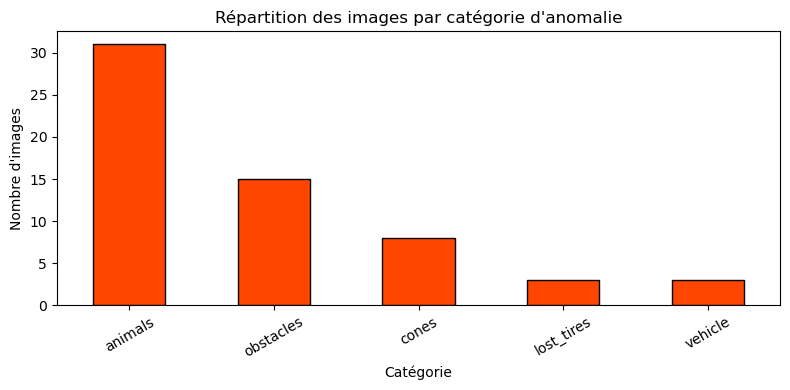

In [ ]:


import re

# Fonction qui garde uniquement les lettres au début du nom (avant les chiffres)
# Exemple : "lost_tires08" -> "lost_tires" ; "cones07" -> "cones"
def get_category(name):
    # ^ = début du nom ; [a-zA-Z_]+? = lettres/underscores, le plus court possible ; \d = premier chiffre
    m = re.match(r"^([a-zA-Z_]+?)\d", name)
    # Si on trouve un motif, on renvoie la catégorie, sinon "autre"
    return m.group(1) if m else "autre"

# On applique la fonction à la colonne "name" du tableau
df["categorie"] = df["name"].apply(get_category)

# Nombre d'images par catégorie
print(df["categorie"].value_counts())

# Statistiques par catégorie : nombre d'images, proportion moyenne d'anomalie,
# et nombre moyen de régions
resume = df.groupby("categorie").agg(
    n_images=("name", "count"),
    anomalie_moy_pct=("prop_anomalie", lambda s: 100 * s.mean()),
    regions_moy=("n_regions", "mean"),
).round(2)
print("\n", resume)

# --- Diagramme en barres du nombre d'images par catégorie ---
plt.figure(figsize=(8, 4))
df["categorie"].value_counts().plot(kind="bar", color="orangered", edgecolor="black")
plt.xlabel("Catégorie")
plt.ylabel("Nombre d'images")
plt.title("Répartition des images par catégorie d'anomalie")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### Interprétation
| Catégorie | Images | Anomalie moyenne | Régions moyennes |
|---|---|---|---|
| animals | 31 | 12,67 % | 5,87 |
| obstacles | 15 | 9,50 % | 8,87 |
| cones | 8 | 2,88 % | 7,50 |
| lost_tires | 3 | 0,69 % | 1,33 |
| vehicle | 3 | 10,20 % | 2,67 |

- **Dataset dominé par les animaux** (31 images sur 60, soit environ 52 %) : le modèle pourrait moins bien généraliser aux autres types d'anomalies.
- **Taille très liée à la catégorie** : les pneus et les cônes sont de petits objets, les animaux sont les plus grands.
- **Deux catégories n'ont que 3 images** : impossible de les répartir proprement sur trois ensembles.

Regrouper les catégories trop petites
`lost_tires` et `vehicle` (3 images chacune) sont regroupées dans un groupe **« autres »** (6 images) pour permettre un découpage stratifié.

In [ ]:

# Catégories assez grandes pour rester seules
grandes = ["animals", "obstacles", "cones"]

# Nouvelle colonne "groupe" : la catégorie si elle est grande, sinon "autres"
df["groupe"] = df["categorie"].apply(lambda c: c if c in grandes else "autres")

# Nombre d'images par groupe
print(df["groupe"].value_counts())

# Pour chaque groupe : proportion moyenne d'anomalie et nombre moyen de régions
print(df.groupby("groupe").agg(
    n_images=("name", "count"),
    anomalie_moy_pct=("prop_anomalie", lambda s: 100 * s.mean()),
    regions_moy=("n_regions", "mean"),
).round(2))

groupe
animals      31
obstacles    15
cones         8
autres        6
Name: count, dtype: int64
           n_images  anomalie_moy_pct  regions_moy
groupe                                            
animals          31             12.67         5.87
autres            6              5.44         2.00
cones             8              2.88         7.50
obstacles        15              9.50         8.87


#### Interprétation
On obtient **4 groupes** : animals (31), obstacles (15), cones (8) et autres (6), soit 60 images. La taille et la fragmentation des anomalies varient fortement selon le groupe (de 2,88 % à 12,67 % de pixels anormaux en moyenne) : **les performances devront donc être analysées par groupe**.

Premier découpage 60 / 20 / 20 stratifié par groupe (version initiale)
La **stratification** garde la même proportion de chaque groupe dans chaque ensemble ; la graine fixe rend le découpage reproductible. Ce premier découpage sera **remplacé** par une version améliorée (sections 5.4 et 5.5).

In [ ]:


from sklearn.model_selection import train_test_split

# Étape 1 : on met de côté 20 % des images pour le test
# stratify=df["groupe"] garde les proportions animals/obstacles/cones/autres
trainval, test = train_test_split(
    df, test_size=0.20, stratify=df["groupe"], random_state=SEED
)

# Étape 2 : sur les 80 % restants, on prend 25 % pour la validation
# (0.25 x 80 % = 20 % du total), le reste (60 %) sert à l'entraînement
train, val = train_test_split(
    trainval, test_size=0.25, stratify=trainval["groupe"], random_state=SEED
)

# On ajoute une colonne "split" au tableau df pour savoir où va chaque image
df["split"] = "train"
df.loc[val.index, "split"] = "val"
df.loc[test.index, "split"] = "test"

# Taille de chaque ensemble
print(df["split"].value_counts())

# Répartition des groupes dans chaque ensemble (doit être proportionnelle)
print("\n", pd.crosstab(df["split"], df["groupe"]))

# Proportion moyenne d'anomalie par ensemble (doit être comparable)
print("\nAnomalie moyenne (%) par ensemble :")
print((df.groupby("split")["prop_anomalie"].mean() * 100).round(2))

# Sauvegarde du split dans un fichier CSV (à citer dans le rapport)
df[["name", "categorie", "groupe", "prop_anomalie", "n_regions", "split"]].to_csv(
    "split.csv", index=False
)
print("\nFichier split.csv sauvegardé.")

split
train    36
val      12
test     12
Name: count, dtype: int64

 groupe  animals  autres  cones  obstacles
split                                    
test          6       1      2          3
train        19       4      4          9
val           6       1      2          3

Anomalie moyenne (%) par ensemble :
split
test      4.94
train    11.18
val      10.77
Name: prop_anomalie, dtype: float64

Fichier split.csv sauvegardé.


#### Interprétation
Les tailles sont correctes (36 / 12 / 12) et les groupes sont répartis proportionnellement, mais **l'anomalie moyenne du test (4,94 %) est deux fois plus petite que celle du train (11,18 %) et de la validation (10,77 %)**. La stratification par groupe ne contrôle pas la taille des anomalies : le test serait artificiellement plus difficile. Ce découpage est donc **abandonné**.

Créer une variable de stratification « groupe + taille d'anomalie »
Chaque image est classée « petite » ou « grande » selon la médiane de la proportion d'anomalie (6,62 %), puis combinée au groupe (par exemple `animals_petite`). Chaque combinaison doit compter au moins 2 images pour que le découpage soit possible.

In [ ]:


# Seuil = médiane de la proportion d'anomalie (6,62 %)
seuil = df["prop_anomalie"].median()

# Variable "taille" : petite si en dessous du seuil, grande sinon
df["taille"] = np.where(df["prop_anomalie"] < seuil, "petite", "grande")

# Variable de stratification combinée, par exemple "animals_petite"
df["strat"] = df["groupe"] + "_" + df["taille"]

# Combien d'images par combinaison (chaque combinaison doit avoir au moins 2 images)
print(df["strat"].value_counts())

strat
animals_grande      20
animals_petite      11
cones_petite         8
obstacles_petite     8
obstacles_grande     7
autres_petite        3
autres_grande        3
Name: count, dtype: int64


#### Interprétation
Les 7 combinaisons comptent chacune **au moins 3 images** : le découpage stratifié est réalisable. À noter que **les 8 images de `cones` sont toutes « petites »**, ce qui confirme que ce sont les anomalies les plus petites du dataset.

Découpage final 60 / 20 / 20 stratifié sur groupe + taille (version retenue)
Ce découpage remplace le précédent et réécrit `split.csv`. Tous les modèles utiliseront exactement les mêmes images d'entraînement, de validation et de test.

In [ ]:


from sklearn.model_selection import train_test_split

# Étape 1 : 20 % des images pour le test, stratifié sur "strat"
trainval, test = train_test_split(
    df, test_size=0.20, stratify=df["strat"], random_state=SEED
)

# Étape 2 : sur les 80 % restants, 25 % pour la validation (= 20 % du total)
train, val = train_test_split(
    trainval, test_size=0.25, stratify=trainval["strat"], random_state=SEED
)

# On réécrit la colonne "split" (l'ancienne valeur est remplacée)
df["split"] = "train"
df.loc[val.index, "split"] = "val"
df.loc[test.index, "split"] = "test"

# Taille de chaque ensemble (attendu : 36 / 12 / 12)
print(df["split"].value_counts())

# Répartition des combinaisons dans chaque ensemble
print("\n", pd.crosstab(df["split"], df["strat"]))

# Anomalie moyenne par ensemble : doit maintenant être comparable
print("\nAnomalie moyenne (%) par ensemble :")
print((df.groupby("split")["prop_anomalie"].mean() * 100).round(2))

# Sauvegarde du nouveau split (on ajoute "taille" et "strat")
df[["name", "categorie", "groupe", "taille", "prop_anomalie", "n_regions", "split"]].to_csv(
    "split.csv", index=False
)
print("\nFichier split.csv mis à jour.")

split
train    36
val      12
test     12
Name: count, dtype: int64

 strat  animals_grande  animals_petite  autres_grande  autres_petite  \
split                                                                 
test                4               2              1              0   
train              12               7              1              2   
val                 4               2              1              1   

strat  cones_petite  obstacles_grande  obstacles_petite  
split                                                    
test              2                 1                 2  
train             5                 4                 5  
val               1                 2                 1  

Anomalie moyenne (%) par ensemble :
split
test      7.57
train    11.04
val       8.56
Name: prop_anomalie, dtype: float64

Fichier split.csv mis à jour.


#### Interprétation
| Ensemble | Images | Anomalie moyenne (avant) | Anomalie moyenne (après) |
|---|---|---|---|
| train | 36 | 11,18 % | 11,04 % |
| val | 12 | 10,77 % | 8,56 % |
| test | 12 | 4,94 % | **7,57 %** |

Le test est maintenant beaucoup plus proche des autres ensembles. L'écart ne disparaît pas totalement, car la séparation petite/grande ne contrôle pas les très grandes valeurs (jusqu'à 42 %).

**Points de vigilance :**
- **Le groupe `autres_petite` n'a aucune image en test** (2 en train, 1 en val) : les petits pneus ne seront pas évalués sur le test.
- **Avec seulement 12 images de test, les métriques seront bruitées.**